<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/D3.%20PTO%20Discrepancy%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D3 Paper PTO Discrepancy

**Diagnostic.** Reads the saved data files and writes two reports; no other file is changed.

Per-ETF regressions on month-end rows (D2) come close to the paper's PTO turnover but fail criterion 1: the paper's turnover is flat across λ, while the per-ETF version still falls as λ rises. This notebook tests three further differences from the replication run's setup, alone and combined:

| Code | Change | Possible effect |
|---|---|---|
| S | Covariance on a daily scale (not × 21) while forecasts are monthly | The risk penalty is 21 times weaker, so turnover ignores λ |
| X | Each ETF's forecast uses every ETF's features (Eq. 29 read literally) | More parameters than rows, so even more inflated forecasts |
| N | Fit on the 9-month part of the window only, not all 12 months | Fewer rows, noisier forecasts |

They are combined with two forecast models: the pooled model (P) and the per-ETF model on month-end rows (E).

**Rule, fixed before the run.** Variants are ordered by the number of changes from the replication run's setup. The first that passes criteria 1 and 2 on ETF_A over the first 70 months counts as the paper's PTO; among variants with the same number of changes, the one closest to the paper's turnover. If none passes, the replication stays partial. Classic Markowitz on the daily scale is also reported, to see whether cause S fits the paper's Markowitz results; it plays no part in the rule.

**Inputs:** Daily Prices, Monthly Data, Daily Features, Daily Training Windows, Covariances

**Outputs** (`data/reports`):

| File | Contents |
|---|---|
| D3 Paper PTO Discrepancy Results.csv | Turnover, volatility and Sharpe ratio of every variant |
| D3 Paper PTO Discrepancy Criteria.csv | Criteria 1 and 2 for every variant |

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: a52e919, Diagnostic (2026-10-30 16:16)



In [2]:
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import backtest, cleaning, config, forecast, windows

# Reload after a fresh clone
for module in (config, cleaning, windows, backtest, forecast):
    importlib.reload(module)

# Data folder paths
DIRS = config.data_dirs()
pd.set_option("display.width", 170)

## 2. Load the inputs

The stored covariances are on the monthly scale (daily estimate × 21); dividing by 21 gives the daily scale used for cause S.

In [3]:
proc = DIRS["processed"]
clean = cleaning.load_clean(proc)
panel = pd.read_parquet(proc / config.FILES["monthly"])
daily_table = pd.read_parquet(proc / config.FILES["daily_table"])
all_windows = pd.read_parquet(proc / config.FILES["daily_windows"])
cov_table = pd.read_parquet(proc / config.FILES["covariances"])

# Decision calendar, holding-month returns, sample covariances and historical means
calendar = all_windows[all_windows["window"] == "9+3"].reset_index(drop=True)
universes = ("ETF_A", "ETF_B")
returns = {u: backtest.holding_returns(panel, u) for u in universes}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in universes}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in universes}

# Daily-scale covariances and historical means for cause S
cov_day = {u: {d: m / config.MONTH_DAYS for d, m in cov_sample[u].items()} for u in universes}
mu_day = {u: hist_mu[u] / config.MONTH_DAYS for u in universes}
paper_pto = backtest.paper_rows("PTO").set_index(["universe", "lam"])
paper_mvo = backtest.paper_rows("MVO").set_index(["universe", "lam"])
print(f"{len(calendar)} decision dates, {calendar['month'].iloc[0]} to {calendar['month'].iloc[-1]}")

81 decision dates, 2020-01 to 2026-09


## 3. Forecast models

| Code | Model | Rows |
|---|---|---|
| P | One ridge model for all ETFs, penalty 0.1 | Daily rows, 12 months |
| E | Least-squares regression per ETF on its own 7 features | Month-end rows, 12 months (about 11) |
| E+N | As E, on the 9-month part only | Month-end rows, 9 months (about 8) |
| E+X | Per-ETF regression on every ETF's features (8 × 7 = 56 inputs) | Month-end rows, 12 months |

Where inputs outnumber rows, least squares has many exact fits; `numpy.linalg.lstsq` returns the one with the smallest coefficients.

In [4]:
def per_etf(universe, cross=False, nine_months=False):
    """Per-ETF least-squares forecasts on month-end rows.

    cross: each ETF's regression uses every ETF's features.
    nine_months: fit on the 9-month part of the window only.
    """
    tickers = backtest.tickers_of(universe)
    rows = []
    for _, step in calendar.iterrows():
        fit, val, test = windows.daily_rows_for(daily_table, step, universe)
        train = fit if nine_months else pd.concat([fit, val])
        train = train[train["month_end"]]
        if cross:
            # One row per month-end, one column per (feature, ETF) pair
            wide = train.pivot(index="date", columns="ticker", values=config.FEATURES)
            target = train.pivot(index="date", columns="ticker", values="fwd_return")
            now = test.set_index("ticker")
            x_now = np.array([now.loc[tk, f] for f, tk in wide.columns], dtype=float)
        for t in tickers:
            if cross:
                x = np.column_stack([np.ones(len(wide)), wide.to_numpy(float)])
                y = target[t].to_numpy(float)
                xt = np.concatenate([[1.0], x_now])
            else:
                tr = train[train["ticker"] == t]
                x = np.column_stack([np.ones(len(tr)), tr[config.FEATURES].to_numpy(float)])
                y = tr["fwd_return"].to_numpy(float)
                xt = np.concatenate([[1.0], test[test["ticker"] == t][config.FEATURES].to_numpy(float)[0]])
            beta, *_ = np.linalg.lstsq(x, y, rcond=None)
            rows.append({"date": step["decision_date"], "month": step["month"], "universe": universe,
                         "ticker": t, "forecast": float(xt @ beta), "rows": len(x), "inputs": x.shape[1]})
    return pd.DataFrame(rows)


models = {}
for u in universes:
    models[("P", u)] = forecast.build_forecasts(daily_table, calendar, u, backtest.tickers_of(u),
                                                alphas=[config.PTO_ALPHA_GRID[0]])
    models[("E", u)] = per_etf(u)
    models[("E+N", u)] = per_etf(u, nine_months=True)
    models[("E+X", u)] = per_etf(u, cross=True)

# Every training return known on its decision date; every forecast finite
label = daily_table.drop_duplicates("date").set_index("date")["label_date"]
assert all(label.loc[s["train_start"]:s["train_end"]].max() <= s["decision_date"] for _, s in calendar.iterrows())
for k, f in models.items():
    assert f["forecast"].notna().all() and np.isfinite(f["forecast"]).all(), k

sizes = pd.DataFrame([{"model": m,
                       "rows per fit": f["rows"].median() if "rows" in f else (f["fit_rows"] + f["validation_rows"]).median(),
                       "inputs": f["inputs"].median() if "inputs" in f else len(config.FEATURES) + len(config.ETF_A) + 1}
                      for (m, u), f in models.items() if u == "ETF_A"])
print(sizes.to_string(index=False))

model  rows per fit  inputs
    P        1848.0    16.0
    E          11.0     8.0
  E+N           8.0     8.0
  E+X          11.0    57.0


## 4. Forecast inflation

Spread ratio: cross-ETF spread of forecasts divided by that of realized returns (1 = the same).

In [5]:
quality = pd.concat([forecast.forecast_quality(f, panel).assign(model=m) for (m, u), f in models.items()])
quality = quality.reset_index().drop_duplicates(["model", "universe"]).set_index(["model", "universe"])
print(quality[["spread_ratio", "mean_ic", "oos_r2", "top_pick_beats_average"]].round(3).to_string())

                spread_ratio  mean_ic    oos_r2  top_pick_beats_average
model universe                                                         
P     ETF_A            0.532    0.120    -0.262                   0.519
E     ETF_A            3.081    0.113    -5.862                   0.605
E+N   ETF_A           23.259    0.076  -825.166                   0.519
E+X   ETF_A            2.036    0.011    -7.138                   0.481
P     ETF_B            0.507   -0.026    -0.419                   0.432
E     ETF_B            2.983   -0.044    -5.488                   0.506
E+N   ETF_B           30.084    0.006 -3495.091                   0.494
E+X   ETF_B            2.974    0.052    -9.768                   0.556


## 5. Backtests

Every forecast model with both covariance scales, for every λ and both universes. Classic Markowitz on the monthly scale and on the daily scale with daily averages.

In [6]:
order = [("P", "monthly"), ("P", "daily"), ("E", "monthly"), ("E", "daily"),
         ("E+N", "monthly"), ("E+X", "monthly"), ("E+N", "daily"), ("E+X", "daily")]
# Number of changes from the replication run's setup
changes = {("P", "monthly"): 0, ("P", "daily"): 1, ("E", "monthly"): 1, ("E", "daily"): 2,
           ("E+N", "monthly"): 2, ("E+X", "monthly"): 2, ("E+N", "daily"): 3, ("E+X", "daily"): 3}

runs = []
for u in universes:
    for m, scale in order:
        mu = models[(m, u)].pivot(index="date", columns="ticker", values="forecast")[backtest.tickers_of(u)]
        cov = cov_sample[u] if scale == "monthly" else cov_day[u]
        for lam in config.LAMBDA_GRID:
            mo, w = backtest.run(backtest.mean_variance(mu, cov, lam), returns[u])
            assert (backtest.check_accounting(mo, w, returns[u])["status"] == "PASS").all()
            runs.append(mo.assign(variant=f"{m}, {scale} cov", universe=u, lam=lam))
    for scale, mu, cov in (("monthly", hist_mu[u], cov_sample[u]), ("daily", mu_day[u], cov_day[u])):
        for lam in config.LAMBDA_GRID:
            mo, w = backtest.run(backtest.mean_variance(mu, cov, lam), returns[u])
            runs.append(mo.assign(variant=f"Markowitz, {scale} scale", universe=u, lam=lam))

months = pd.concat(runs, ignore_index=True)
first70 = months[months["month"] <= config.PAPER_LAST_MONTH]
summary = pd.DataFrame([backtest.metrics(g).rename(k) for k, g in first70.groupby(["variant", "universe", "lam"])])
summary.index.names = ["variant", "universe", "lam"]

names = [f"{m}, {s} cov" for m, s in order]
view = summary["turnover"].unstack("variant")[names + ["Markowitz, monthly scale", "Markowitz, daily scale"]]
view["paper PTO"] = paper_pto["turnover"]
view["paper MVO"] = paper_mvo["turnover"]
print("Monthly turnover, first 70 months")
print(view.round(3).T.to_string())

Monthly turnover, first 70 months
universe                  ETF_A                              ETF_B                            
lam                        0.1    1.0    10.0   20.0   50.0   0.1    1.0    10.0   20.0   50.0
variant                                                                                       
P, monthly cov            0.341  0.348  0.282  0.198  0.103  0.399  0.415  0.313  0.205  0.113
P, daily cov              0.341  0.341  0.348  0.350  0.350  0.399  0.399  0.405  0.419  0.392
E, monthly cov            0.741  0.753  0.787  0.741  0.625  0.829  0.824  0.833  0.798  0.690
E, daily cov              0.741  0.741  0.750  0.753  0.775  0.827  0.827  0.828  0.824  0.822
E+N, monthly cov          0.798  0.798  0.817  0.813  0.764  0.813  0.799  0.769  0.783  0.820
E+X, monthly cov          0.654  0.641  0.615  0.535  0.380  0.754  0.761  0.776  0.747  0.634
E+N, daily cov            0.798  0.798  0.798  0.798  0.788  0.813  0.813  0.799  0.799  0.799
E+X, daily cov  

## 6. Turnover across λ

The paper's PTO turnover (black) is flat across λ.

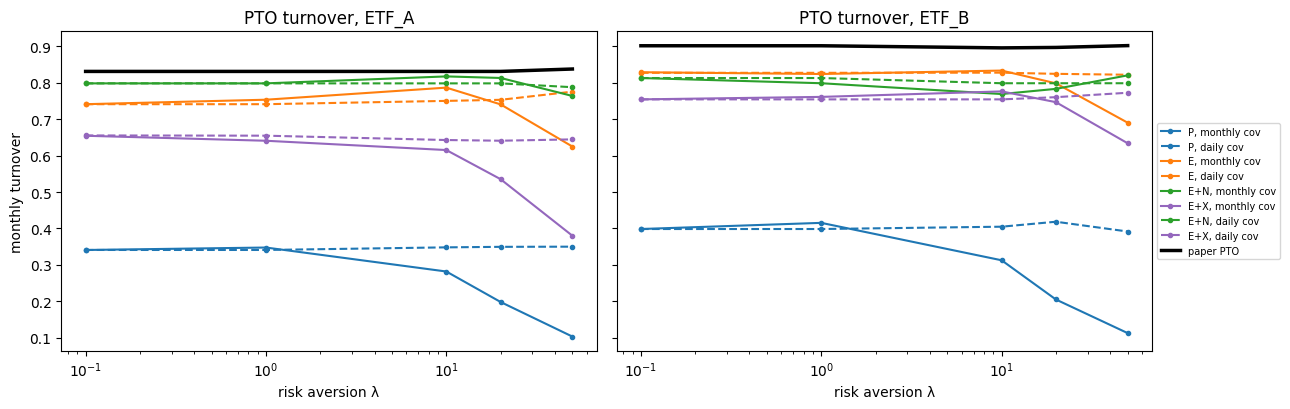

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
styles = {"monthly": "-", "daily": "--"}
colors = {"P": "tab:blue", "E": "tab:orange", "E+N": "tab:green", "E+X": "tab:purple"}
for ax, u in zip(axes, universes):
    for m, s in order:
        t = summary.loc[(f"{m}, {s} cov", u)]["turnover"]
        ax.plot(t.index, t.values, styles[s], marker="o", ms=3, color=colors[m], label=f"{m}, {s} cov")
    ax.plot(paper_pto.loc[u].index, paper_pto.loc[u]["turnover"], color="black", lw=2.5, label="paper PTO")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"PTO turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

## 7. Criteria and the rule

In [8]:
hi = [l for l in config.LAMBDA_GRID if l >= 10]
mvo = summary.loc[("Markowitz, monthly scale", "ETF_A")]
rows = []
for m, s in order:
    a = summary.loc[(f"{m}, {s} cov", "ETF_A")].sort_index()
    change = abs(a.loc[50.0, "turnover"] - a.loc[0.1, "turnover"])
    ratio = a.loc[hi, "turnover"] / mvo.loc[hi, "turnover"]
    gap = (a["turnover"] - paper_pto.loc["ETF_A"]["turnover"]).abs().mean()
    rows.append({"variant": f"{m}, {s} cov", "changes": changes[(m, s)],
                 "turnover": f"{a['turnover'].min():.2f} to {a['turnover'].max():.2f}",
                 "change λ 0.1 to 50": round(change, 3),
                 "ratio to Markowitz, λ ≥ 10": ", ".join(f"{r:.1f}" for r in ratio),
                 "gap to paper": round(gap, 3),
                 "criterion 1": "PASS" if (a["turnover"] >= 0.6).all() and change < 0.1 else "FAIL",
                 "criterion 2": "PASS" if (ratio >= 3).all() else "FAIL",
                 "mean Sharpe": round(a["sharpe"].mean(), 3)})
crit = pd.DataFrame(rows)
print(crit.to_string(index=False))
print()

ok = crit[(crit["criterion 1"] == "PASS") & (crit["criterion 2"] == "PASS")]
if len(ok):
    best = ok.sort_values(["changes", "gap to paper"]).iloc[0]
    print(f"Rule: '{best['variant']}' is the simplest variant that reproduces the paper's PTO "
          f"({best['changes']} changes, mean gap {best['gap to paper']:.3f}).")
else:
    print("Rule: no variant passes both criteria. The replication stays partial.")

         variant  changes     turnover  change λ 0.1 to 50 ratio to Markowitz, λ ≥ 10  gap to paper criterion 1 criterion 2  mean Sharpe
  P, monthly cov        0 0.10 to 0.35               0.238              2.2, 2.4, 2.3         0.578        FAIL        FAIL        0.215
    P, daily cov        1 0.34 to 0.35               0.009              2.7, 4.3, 7.7         0.486        FAIL        FAIL        0.455
  E, monthly cov        1 0.62 to 0.79               0.116             6.2, 9.1, 13.7         0.103        FAIL        PASS        0.201
    E, daily cov        2 0.74 to 0.78               0.034             5.9, 9.3, 17.0         0.080        PASS        PASS        0.320
E+N, monthly cov        2 0.76 to 0.82               0.035            6.4, 10.0, 16.7         0.034        PASS        PASS        0.019
E+X, monthly cov        2 0.38 to 0.65               0.274              4.8, 6.6, 8.3         0.267        FAIL        PASS        0.050
  E+N, daily cov        3 0.79 to 0.80   

## 8. Cause S and the paper's Markowitz

On the daily scale, classic Markowitz uses daily averages and a daily covariance; scaling both down by 21 makes the trading penalty 21 times larger relative to returns.

In [9]:
mk = pd.concat([summary.loc[f"Markowitz, {s} scale"][["turnover", "ann_vol", "sharpe"]].add_prefix(f"{s}: ")
                for s in ("monthly", "daily")], axis=1)
mk = mk.join(paper_mvo[["turnover", "ann_vol", "sharpe"]].add_prefix("paper: "))
print(mk.round(3).to_string())

               monthly: turnover  monthly: ann_vol  monthly: sharpe  daily: turnover  daily: ann_vol  daily: sharpe  paper: turnover  paper: ann_vol  paper: sharpe
universe lam                                                                                                                                                       
ETF_A    0.1               0.170             0.196            0.717            0.000           0.138          0.867            0.194           0.248          0.654
         1.0               0.180             0.178            0.780            0.000           0.138          0.867            0.248           0.236          0.440
         10.0              0.127             0.097            0.519            0.000           0.138          0.867            0.142           0.108          0.285
         20.0              0.081             0.072            0.392            0.003           0.117          0.719            0.091           0.078          0.248
         50.0   

## 9. Save

In [10]:
summary.reset_index().to_csv(DIRS["reports"] / "D3 Paper PTO Discrepancy Results.csv", index=False)
crit.to_csv(DIRS["reports"] / "D3 Paper PTO Discrepancy Criteria.csv", index=False)